In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.append("../..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import xarray as xr

from cordex2energy.utils.plotting import (
    plot_gmst_anomalies,
    plot_gmst_anomalies_subset_vs_all
)


sns.set_style("whitegrid", {"grid.color": ".93"})

In [3]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])
path_data_gcm = Path("/net/atmos/data/cmip5-ng/")
path_data_cmip5 = Path("/net/atmos/data/cmip5/")

path_figs = Path("../../figs")
(path_figs / "driving_gcms").mkdir(parents=True, exist_ok=True)

# Load GCM data

In [4]:
gcms = ["CNRM-CM5_r1i1p1", "HadGEM2-ES_r1i1p1", "NorESM1-M_r1i1p1", "MPI-ESM-LR_r1i1p1", "EC-EARTH_r12i1p1"]
ensemble_members = [gcm.split("_")[-1] for gcm in gcms]
gcms = [gcm.split("_")[0] for gcm in gcms]

In [5]:
xr.open_dataset("/net/atmos/data/cmip5/historical/Amon/tas/CNRM-CM5/r1i1p1/tas_Amon_CNRM-CM5_historical_r1i1p1_185001-189912.nc")

<xarray.Dataset> Size: 79MB
Dimensions:    (time: 600, bnds: 2, lat: 128, lon: 256)
Coordinates:
  * time       (time) datetime64[ns] 5kB 1850-01-16T12:00:00 ... 1899-12-16T1...
  * lat        (lat) float64 1kB -88.93 -87.54 -86.14 ... 86.14 87.54 88.93
  * lon        (lon) float64 2kB 0.0 1.406 2.812 4.219 ... 355.8 357.2 358.6
    height     float64 8B ...
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 10kB ...
    lat_bnds   (lat, bnds) float64 2kB ...
    lon_bnds   (lon, bnds) float64 4kB ...
    tas        (time, lat, lon) float32 79MB ...
Attributes: (12/28)
    institution:            CNRM (Centre National de Recherches Meteorologiqu...
    institute_id:           CNRM-CERFACS
    experiment_id:          historical
    source:                 CNRM-CM5 2010 Atmosphere: ARPEGE-Climat (V5.2.1, ...
    model_id:               CNRM-CM5
    forcing:                GHG, SA, Sl, Vl, BC, OC
    ...                     ...
    table_id:               Table Amon (31 January 2011) 53b766a395ac41696af4...
    title:                  CNRM-CM5 model output prepared for CMIP5 historical
    parent_experiment:      pre-industrial control
    modeling_realm:         atmos
    realization:            1
    cmor_version:           2.5.3

In [6]:
var = "tas"
temp_res = "ann"
scenarios = ["rcp26", "rcp45", "rcp85"]

subset_gcms = []
for gcm, ens in zip(gcms, ensemble_members):
    for scenario in scenarios:
        subset_gcms.extend(sorted(path_data_gcm.glob(f"{var}/*{temp_res}_{gcm}_{scenario}_*{ens}*_g025.nc")))

len(subset_gcms)

15

In [7]:
all_other_gcms_data = []
for scenario in scenarios:
    all_other_gcms_data.extend(
        sorted(path_data_gcm.glob(f"{var}/*{temp_res}*{scenario}_*_g025.nc"))
    )
# Remove all elements in matches from all_other_gcms_data
all_other_gcms_data = [item for item in all_other_gcms_data if item not in subset_gcms]
len(all_other_gcms_data)

251

# Plot

In [8]:
reference_period = slice("1871", "1900")

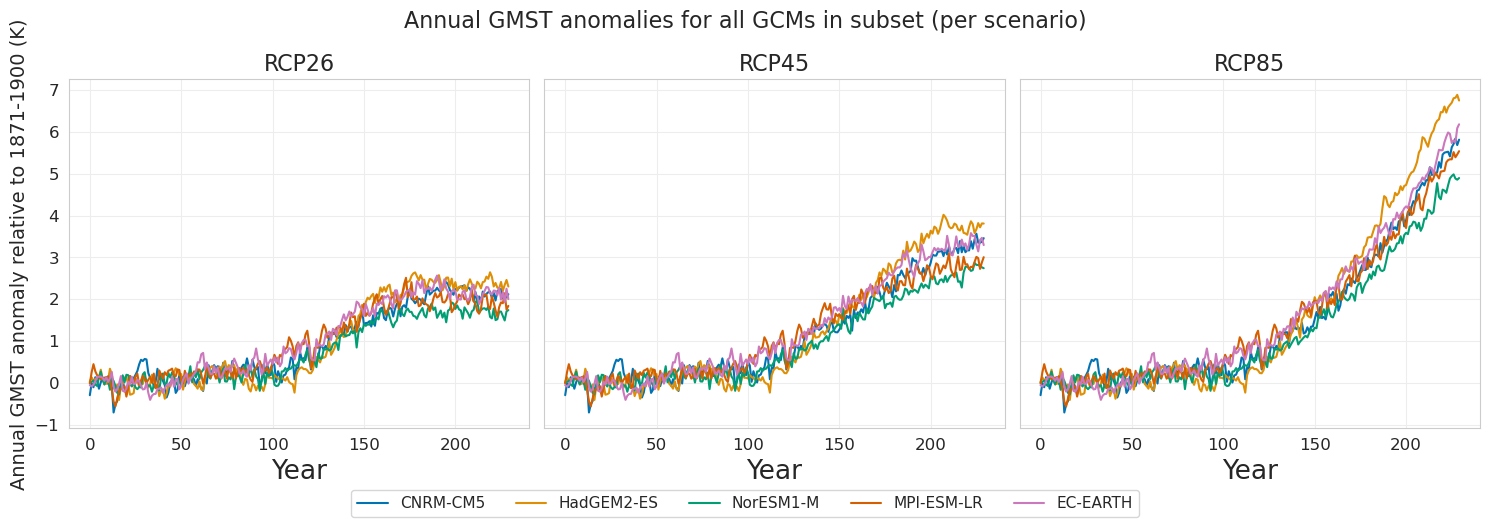

In [9]:
components_size_config = {
    "FONTSIZE_LEGEND": 11,
    "FONTSIZE_TICKS": 12,
    "FONTSIZE_LABELS": 14,
    "FONTSIZE_TITLE": 16,
}

plot_gmst_anomalies(
    scenarios=scenarios,
    subset_gcms=subset_gcms,
    var=var,
    reference_period=reference_period,
    time_dim="time",
    figsize=(15, 5),
    components_size_config=components_size_config,
    # path_savefig=path_figs / "driving_gcms" / "annual_gmst_subset_anomalies.png"
)

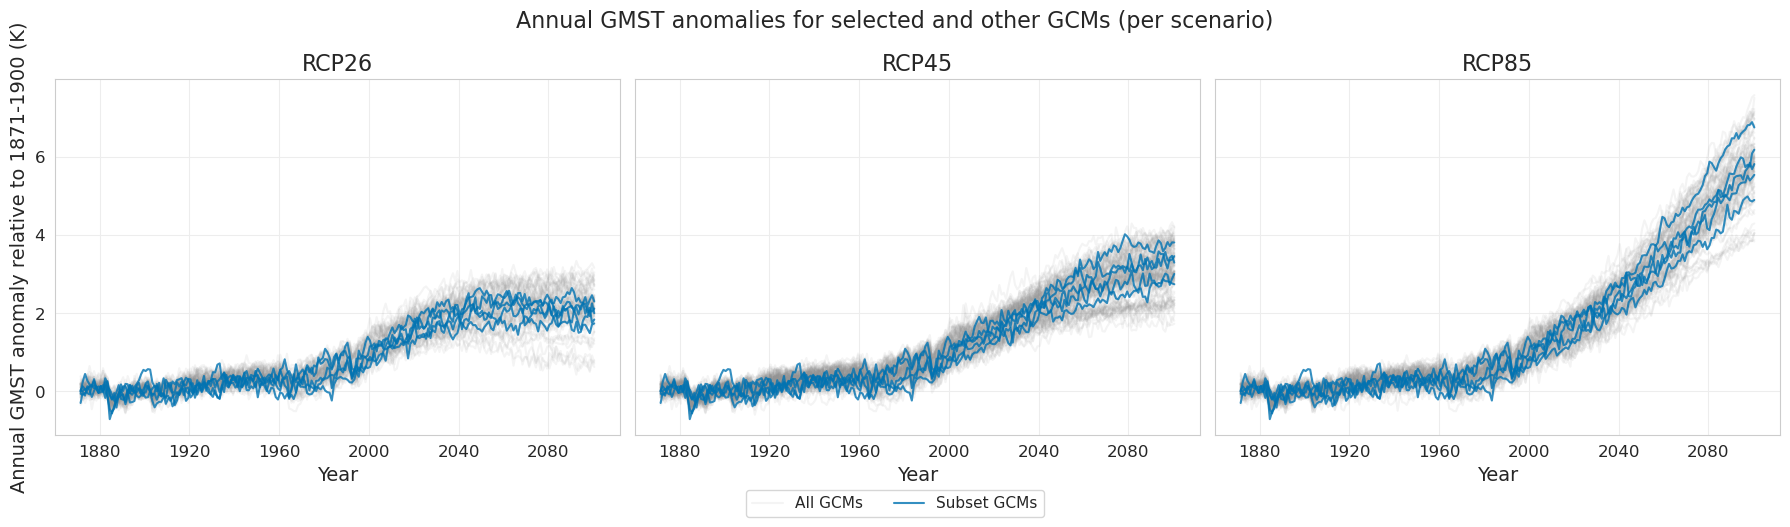

In [10]:
plot_gmst_anomalies_subset_vs_all(
    scenarios=scenarios,
    subset_gcms=subset_gcms,
    all_other_gcms_data=all_other_gcms_data,
    var=var,
    reference_period=reference_period,
    components_size_config=components_size_config,
    time_dim="year",
    figsize=(18, 5),
    # path_savefig=path_figs / "driving_gcms" / "annual_gmst_all_gcms_anomalies_individual_subset.png"
    separate_subset=False
)

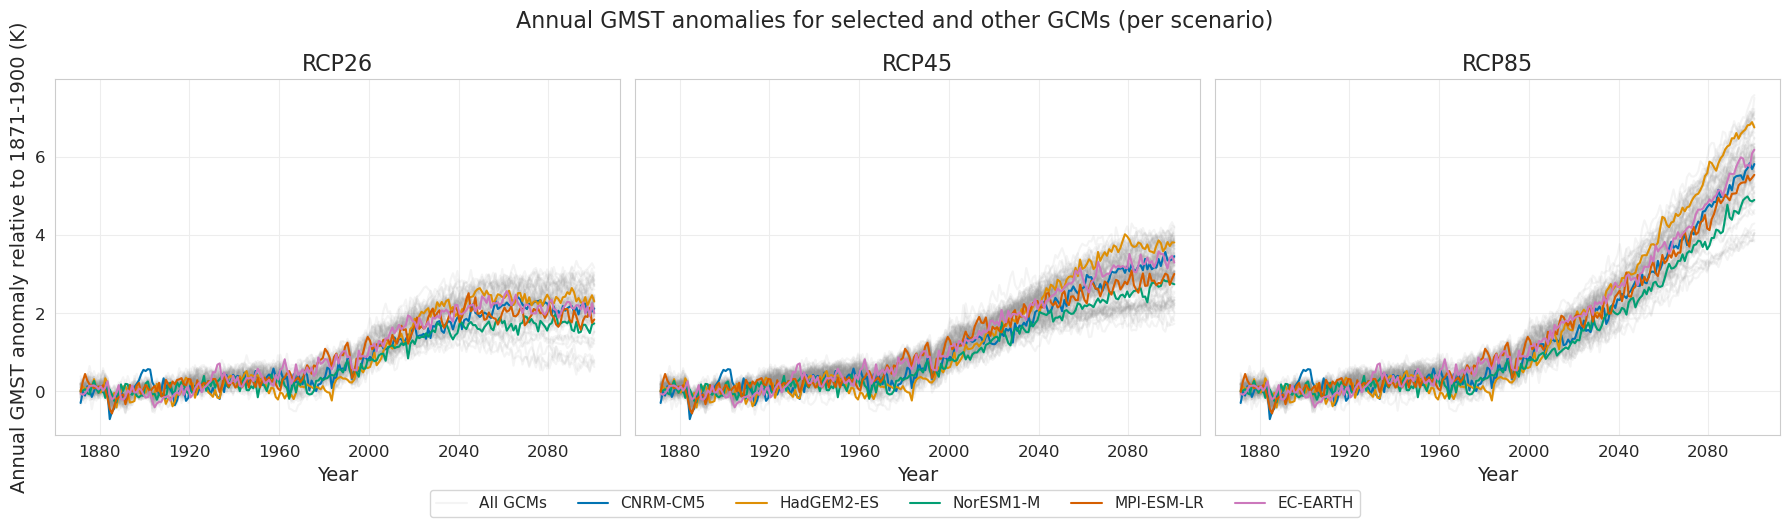

In [11]:
plot_gmst_anomalies_subset_vs_all(
    scenarios=scenarios,
    subset_gcms=subset_gcms,
    all_other_gcms_data=all_other_gcms_data,
    var=var,
    reference_period=reference_period,
    time_dim="year",
    figsize=(18, 5),
    components_size_config=components_size_config,
    path_savefig=path_figs / "driving_gcms" / "annual_gmst_all_gcms_anomalies_individual_subset.png",
    separate_subset=True
)

# Global Warming Levels

Warming-level periods are read directly from the pre-computed file
`cmip5_warming_levels_all_ens_1850_1900.yml` (Mathias Hauser, 2024-04-22).
Reference baseline: **1861–1900**.

For each model/scenario the file stores the 20-year window (`start_year`–`end_year`)
centred on the first year where the 20-year running-mean GMST anomaly first exceeded
the threshold.  `central_year = start_year + 10`.

> **Note:** HadGEM2-ES is absent from this file (will show `—`).
> NorESM1-M does not reach 1.5 °C under rcp26.

In [12]:
import pandas as pd
from cordex2energy.utils.plotting import load_warming_level_periods

warming_levels = [1.0, 1.5, 2.0, 3.0]
_gcm_ens = dict(zip(gcms, ensemble_members))  # {"CNRM-CM5": "r1i1p1", ...}

gwl_results = load_warming_level_periods(
    yml_path=path_data_processed / "cmip5_warming_levels_all_ens_1850_1900.yml",
    warming_levels=warming_levels,
    gcms=_gcm_ens,
)

# Preview as a flat DataFrame
rows = []
for (model, ens), scen_dict in gwl_results.items():
    for scenario, wl_dict in scen_dict.items():
        for wl, r in wl_dict.items():
            rows.append({"model": model, "ensemble": ens, "scenario": scenario,
                         "warming_level": wl, **r})
pd.DataFrame(rows).sort_values(["model", "ensemble", "scenario", "warming_level"]).reset_index(drop=True)

,model,ensemble,scenario,warming_level,start_year,end_year,central_year
0,CNRM-CM5,r1i1p1,rcp26,1.0,2003,2022,2013
1,CNRM-CM5,r1i1p1,rcp26,1.5,2034,2053,2044
2,CNRM-CM5,r1i1p1,rcp45,1.0,2002,2021,2012
3,CNRM-CM5,r1i1p1,rcp45,1.5,2028,2047,2038
4,CNRM-CM5,r1i1p1,rcp45,2.0,2049,2068,2059
5,CNRM-CM5,r1i1p1,rcp85,1.0,2002,2021,2012
6,CNRM-CM5,r1i1p1,rcp85,1.5,2021,2040,2031
7,CNRM-CM5,r1i1p1,rcp85,2.0,2036,2055,2046
8,CNRM-CM5,r1i1p1,rcp85,3.0,2058,2077,2068
9,EC-EARTH,r12i1p1,rcp26,1.0,1994,2013,2004


In [13]:
rows = []
for gcm, ens in zip(gcms, ensemble_members):
    for scenario in scenarios:
        for wl in warming_levels:
            r = gwl_results.get((gcm, ens), {}).get(scenario, {}).get(wl)
            label = f"{r['central_year']}  ({r['start_year']}–{r['end_year']})" if r else "—"
            rows.append({"GCM": gcm, "Ensemble": ens, "Scenario": scenario,
                         "WL": f"+{wl} °C", "value": label})

df = pd.DataFrame(rows)
df_table = df.pivot_table(
    index=["GCM", "Ensemble", "Scenario"], columns="WL", values="value", aggfunc="first"
)
df_table = df_table[[f"+{wl} °C" for wl in warming_levels]]
df_table

WL                                      +1.0 °C            +1.5 °C  \
GCM        Ensemble Scenario                                         
CNRM-CM5   r1i1p1   rcp26     2013  (2003–2022)  2044  (2034–2053)   
                    rcp45     2012  (2002–2021)  2038  (2028–2047)   
                    rcp85     2012  (2002–2021)  2031  (2021–2040)   
EC-EARTH   r12i1p1  rcp26     2004  (1994–2013)  2024  (2014–2033)   
                    rcp45     2004  (1994–2013)  2023  (2013–2032)   
                    rcp85     2004  (1994–2013)  2019  (2009–2028)   
HadGEM2-ES r1i1p1   rcp26                     —                  —   
                    rcp45                     —                  —   
                    rcp85                     —                  —   
MPI-ESM-LR r1i1p1   rcp26     2004  (1994–2013)  2023  (2013–2032)   
                    rcp45     2003  (1993–2012)  2023  (2013–2032)   
                    rcp85     2003  (1993–2012)  2018  (2008–2027)   
NorESM1-M  r1i1p1   rcp26     2018  (2008–2027)                  —   
                    rcp45     2019  (2009–2028)  2040  (2030–2049)   
                    rcp85     2017  (2007–2026)  2033  (2023–2042)   

WL                                      +2.0 °C            +3.0 °C  
GCM        Ensemble Scenario                                        
CNRM-CM5   r1i1p1   rcp26                     —                  —  
                    rcp45     2059  (2049–2068)                  —  
                    rcp85     2046  (2036–2055)  2068  (2058–2077)  
EC-EARTH   r12i1p1  rcp26                     —                  —  
                    rcp45     2045  (2035–2054)                  —  
                    rcp85     2035  (2025–2044)  2061  (2051–2070)  
HadGEM2-ES r1i1p1   rcp26                     —                  —  
                    rcp45                     —                  —  
                    rcp85                     —                  —  
MPI-ESM-LR r1i1p1   rcp26                     —                  —  
                    rcp45     2045  (2035–2054)                  —  
                    rcp85     2038  (2028–2047)  2062  (2052–2071)  
NorESM1-M  r1i1p1   rcp26                     —                  —  
                    rcp45     2074  (2064–2083)                  —  
                    rcp85     2049  (2039–2058)  2074  (2064–2083)

# Global Warming Level around 2050 (direct computation from raw CMIP5 data)

Computed directly from the native-grid monthly `tas` files under `path_data_cmip5`
(`{scenario}/Amon/tas/{gcm}/{ens}/tas_Amon_{gcm}_{scenario}_{ens}_*.nc`), concatenating
`historical` with each `rcpXX` scenario.

- Global mean is area-weighted by `cos(latitude)` (native grids are Gaussian, not equal-area).
- Annual means are weighted by days-per-month (via each file's own calendar).
- Anomaly baseline: **1850–1899** global mean.
- GWL around 2050 = mean anomaly over **2040–2060**.

> **Note:** HadGEM2-ES's historical run only starts in Dec 1859, so its 1850–1899
> baseline is actually computed over 1860–1899 (flagged in the table).

In [21]:
def annual_global_mean_tas(path_data_cmip5, gcm, ens, scenario, var="tas"):
    """Area- and calendar-weighted annual global-mean tas for historical+scenario."""
    hist_dir = path_data_cmip5 / "historical" / "Amon" / var / gcm / ens
    scen_dir = path_data_cmip5 / scenario / "Amon" / var / gcm / ens
    files = sorted(hist_dir.glob(f"{var}_Amon_{gcm}_historical_{ens}_*.nc")) + sorted(
        scen_dir.glob(f"{var}_Amon_{gcm}_{scenario}_{ens}_*.nc")
    )
    if not files:
        return None

    ds = xr.open_mfdataset(
        files, combine="nested", concat_dim="time", data_vars="minimal", coords="minimal",
        decode_times=xr.coders.CFDatetimeCoder(use_cftime=True),
    ).sortby("time")
    weights = np.cos(np.deg2rad(ds.lat))
    global_mean = ds[var].weighted(weights).mean(dim=["lat", "lon"])

    days = global_mean.time.dt.days_in_month
    annual = (global_mean * days).groupby("time.year").sum() / days.groupby("time.year").sum()
    annual = annual.compute()
    ds.close()
    return annual


def global_warming_level(annual, baseline=(1850, 1899), target_years=(2040, 2060)):
    """GWL = mean anomaly over target_years relative to the baseline-period mean."""
    available_years = annual["year"].values
    baseline_years = [y for y in range(baseline[0], baseline[1] + 1) if y in available_years]
    ref_mean = annual.sel(year=baseline_years).mean()
    anomaly = annual - ref_mean
    gwl = anomaly.sel(year=slice(target_years[0], target_years[1])).mean()
    return float(gwl), (min(baseline_years), max(baseline_years))

In [22]:
rows = []
annual_cache = {}  # (gcm, ens, scenario) -> annual DataArray, reused for plotting below

for gcm, ens in zip(gcms, ensemble_members):
    for scenario in scenarios:
        annual = annual_global_mean_tas(path_data_cmip5, gcm, ens, scenario)
        if annual is None:
            rows.append({"GCM": gcm, "Ensemble": ens, "Scenario": scenario,
                         "GWL_2050": None, "baseline_period": None})
            continue
        annual_cache[(gcm, ens, scenario)] = annual
        gwl, baseline_used = global_warming_level(annual)
        rows.append({
            "GCM": gcm, "Ensemble": ens, "Scenario": scenario,
            "GWL_2050": round(gwl, 2),
            "baseline_period": f"{baseline_used[0]}-{baseline_used[1]}",
        })

gwl_2050_df = pd.DataFrame(rows)
gwl_2050_df

/tmp/ipykernel_7444/2397565422.py:11: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ds = xr.open_mfdataset(
/tmp/ipykernel_7444/2397565422.py:11: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ds = xr.open_mfdataset(
/tmp/ipykernel_7444/2397565422.py:11: FutureWarning: In a future version of xarray the default value for compat will cha

,GCM,Ensemble,Scenario,GWL_2050,baseline_period
0,CNRM-CM5,r1i1p1,rcp26,1.60,1850-1899
1,CNRM-CM5,r1i1p1,rcp45,1.84,1850-1899
2,CNRM-CM5,r1i1p1,rcp85,2.23,1850-1899
3,HadGEM2-ES,r1i1p1,rcp26,1.94,1859-1899
4,HadGEM2-ES,r1i1p1,rcp45,2.24,1859-1899
5,HadGEM2-ES,r1i1p1,rcp85,2.77,1859-1899
6,NorESM1-M,r1i1p1,rcp26,1.41,1850-1899
7,NorESM1-M,r1i1p1,rcp45,1.68,1850-1899
8,NorESM1-M,r1i1p1,rcp85,2.05,1850-1899
9,MPI-ESM-LR,r1i1p1,rcp26,1.76,1850-1899


In [23]:
gwl_2050_df.pivot_table(
    index=["GCM", "Ensemble"], columns="Scenario", values="GWL_2050", aggfunc="first"
)[scenarios]

,Scenario,rcp26,rcp45,rcp85
GCM,Ensemble,,,
CNRM-CM5,r1i1p1,1.60,1.84,2.23
EC-EARTH,r12i1p1,1.82,2.15,2.60
HadGEM2-ES,r1i1p1,1.94,2.24,2.77
MPI-ESM-LR,r1i1p1,1.76,2.07,2.55
NorESM1-M,r1i1p1,1.41,1.68,2.05


In [25]:
gwl_2050_df.pivot_table(
    index=["GCM", "Ensemble"], columns="Scenario", values="GWL_2050", aggfunc="first"
)[scenarios].mean(axis=0)

Scenario
rcp26    1.706
rcp45    1.996
rcp85    2.440
dtype: float64